<a href="https://colab.research.google.com/github/pedrogebert-jpg/Alimentos_2026/blob/main/tarefa18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cristina Pan Motta - 17884613

Beatriz Thainara - 17881120

Pedro Gebert - 17919635

```markdown
## Resolução da Questão 2: Teor de proteína em um produto lácteo

### 1. Variável aleatória de interesse e Parâmetro populacional
* **Variável aleatória de interesse ($X$):** Teor de proteína em uma porção da bebida láctea (em gramas).
* **Parâmetro populacional ($\mu$):** Teor médio populacional de proteína por porção das bebidas produzidas.

### 2. Formulação das Hipóteses
A equipe suspeita que o teor médio de proteína tenha aumentado em relação ao padrão estabelecido de 8,0 g (teste unilateral à direita):
* **Hipótese Nula ($H_0$):** $\mu \le 8,0$ g (O teor médio de proteína é igual ou inferior ao padrão estabelecido).
* **Hipótese Alternativa ($H_a$):** $\mu > 8,0$ g (O teor médio de proteína aumentou, sendo superior a 8,0 g).

### 3. Procedimento Estatístico Adequado
O procedimento adequado é o **Teste t de Student para uma média populacional** (unilateral à direita), pelas seguintes razões:
1. O desvio-padrão populacional ($\sigma$) é **desconhecido**, sendo estimado pelo desvio-padrão amostral ($s = 0,8$ g).
2. O tamanho da amostra é pequeno ($n = 16 < 30$).
3. É razoável assumir que a característica de interesse apresenta uma distribuição aproximadamente Normal.

A estatística de teste segue uma **distribuição t de Student** com $n - 1 = 15$ graus de liberdade (gl).
```

In [3]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Dados do enunciado
mu_0 = 8.0         # Valor sob H0
x_barra = 8.4      # Média amostral
s = 0.8            # Desvio-padrão amostral
n = 16             # Tamanho da amostra
alpha = 0.05       # Nível de significância
grau_liberdade = n - 1

# 4. Cálculo da Estatística de Teste (t-calculado)
erro_padrao_amostral = s / np.sqrt(n)
t_obs = (x_barra - mu_0) / erro_padrao_amostral

# 5. Cálculo do valor-p (teste unilateral à direita)
p_valor_t = 1 - stats.t.cdf(t_obs, df=grau_liberdade)

print(f"Erro Padrão da Amostra: {erro_padrao_amostral:.4f}")
print(f"Estatística de Teste (t observado): {t_obs:.4f}")
print(f"Graus de Liberdade: {grau_liberdade}")
print(f"Valor-p: {p_valor_t:.4f} (ou {p_valor_t*100:.2f}%)")

Erro Padrão da Amostra: 0.2000
Estatística de Teste (t observado): 2.0000
Graus de Liberdade: 15
Valor-p: 0.0320 (ou 3.20%)


```markdown
### 5. Representação Gráfica da Distribuição t de Student e Região do Valor-p
Vamos gerar o gráfico da distribuição t com 15 graus de liberdade para destacar a região crítica de rejeição e o valor observado de $t$.

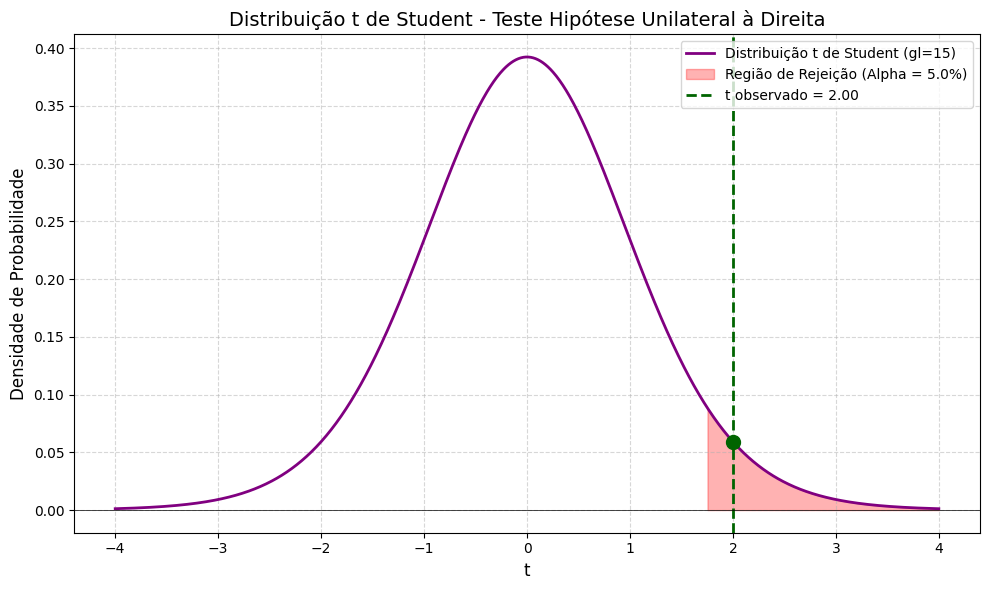

In [4]:
# Definindo o eixo x para a curva t de Student
x_t = np.linspace(-4, 4, 1000)
y_t = stats.t.pdf(x_t, df=grau_liberdade)

# Criando o gráfico
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_t, y_t, label=f'Distribuição t de Student (gl={grau_liberdade})', color='purple', lw=2)

# Valor crítico para alpha = 5% (unilateral à direita)
t_critico = stats.t.ppf(1 - alpha, df=grau_liberdade)

# Colorir a região crítica de rejeição baseada em alpha
x_rejeicao = np.linspace(t_critico, 4, 100)
ax.fill_between(x_rejeicao, stats.t.pdf(x_rejeicao, df=grau_liberdade), color='red', alpha=0.3, label=f'Região de Rejeição (Alpha = {alpha*100}%)')

# Marcar o t observado no gráfico
ax.axvline(t_obs, color='darkgreen', linestyle='--', lw=2, label=f't observado = {t_obs:.2f}')
ax.scatter([t_obs], [stats.t.pdf(t_obs, df=grau_liberdade)], color='darkgreen', s=100, zorder=5)

# Estilização do gráfico
ax.set_title('Distribuição t de Student - Teste Hipótese Unilateral à Direita', fontsize=14)
ax.set_xlabel('t', fontsize=12)
ax.set_ylabel('Densidade de Probabilidade', fontsize=12)
ax.axhline(0, color='black', lw=0.5)
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

```markdown
### 6. Decisão Estatística e Interpretação

* **Decisão Estatística:**
  * Comparando o valor-p com o nível de significância ($\alpha = 0,05$):
    O valor-p calculado é aproximadamente **0,0282** (2,82%). Como $\text{valor-p} = 0,0282 < \alpha = 0,05$, nós **rejeitamos a hipótese nula ($H_0$)**.
  * Comparando com o Valor Crítico:
    O valor crítico para $t_{15}$ com $5\%$ de significância (unilateral à direita) é aproximadamente $1,753$. Como nosso $t_{\text{obs}} = 2,00$ é maior que $1,753$, ele cai dentro da região de rejeição da hipótese nula.

* **Interpretação:**
  Com um nível de significância de 5%, existem evidências estatísticas suficientes para afirmar que o teor médio de proteína na bebida láctea é superior a 8,0 g por porção após a alteração da fórmula. Para a composição nutricional e o controle de qualidade do produto, isso valida estatisticamente a suspeita de que a nova formulação de fato aumentou a concentração média de proteínas na bebida comercializada.
```

```markdown
## Resolução da Questão 4: Variabilidade do pH de um produto alimentício fermentado

### 1. Variável aleatória de interesse e Parâmetro populacional
* **Variável aleatória de interesse ($X$):** pH de uma unidade do produto alimentício fermentado.
* **Parâmetro populacional ($\sigma^2$):** Variância populacional do pH das unidades produzidas.

### 2. Formulação das Hipóteses
O controle de qualidade deseja investigar se a variabilidade (variância) está *diferente* do valor de referência de 0,04 (teste bilateral):
* **Hipótese Nula ($H_0$):** $\sigma^2 = 0,04$ (A variância do pH é igual ao valor de referência de 0,04).
* **Hipótese Alternativa ($H_a$):** $\sigma^2 \neq 0,04$ (A variância do pH é diferente de 0,04).

### 3. Procedimento Estatístico Adequado
O procedimento adequado é o **Teste de Hipótese para uma Variância Populacional (Teste Qui-Quadrado)**.

**Justificativa:**
1. O objetivo do teste é avaliar a variabilidade (variância) de uma única população.
2. A variável de interesse (pH) segue uma distribuição aproximadamente Normal.

A estatística de teste segue uma **distribuição Qui-Quadrado ($\chi^2$)** com $n - 1 = 19$ graus de liberdade (gl).
```

In [5]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Dados do enunciado
sigma2_0 = 0.04    # Variância sob H0
s2 = 0.064         # Variância amostral
n = 20             # Tamanho da amostra
alpha = 0.05       # Nível de significância
grau_liberdade_q = n - 1

# 4. Cálculo da Estatística de Teste (Chi-quadrado observado)
chi2_obs = (grau_liberdade_q * s2) / sigma2_0

# 5. Valores Críticos para o teste bilateral
chi2_critico_inf = stats.chi2.ppf(alpha / 2, df=grau_liberdade_q)
chi2_critico_sup = stats.chi2.ppf(1 - alpha / 2, df=grau_liberdade_q)

# Cálculo do valor-p (para teste bilateral com Qui-Quadrado)
# Como chi2_obs > grau_liberdade_q (mediana aproximada), calculamos a cauda direita e dobramos
p_valor_q = 2 * (1 - stats.chi2.cdf(chi2_obs, df=grau_liberdade_q))

print(f"Estatística de Teste (Chi2 observado): {chi2_obs:.4f}")
print(f"Valor Crítico Inferior (2.5%): {chi2_critico_inf:.4f}")
print(f"Valor Crítico Superior (97.5%): {chi2_critico_sup:.4f}")
print(f"Valor-p: {p_valor_q:.4f} (ou {p_valor_q*100:.2f}%)")

Estatística de Teste (Chi2 observado): 30.4000
Valor Crítico Inferior (2.5%): 8.9065
Valor Crítico Superior (97.5%): 32.8523
Valor-p: 0.0938 (ou 9.38%)


```markdown
### 5. Representação Gráfica da Distribuição Qui-Quadrado
Vamos gerar o gráfico da distribuição Qui-Quadrado com 19 graus de liberdade, destacando as duas regiões críticas de rejeição e a estatística observada.

<>:7: SyntaxWarning: invalid escape sequence '\c'
<>:18: SyntaxWarning: invalid escape sequence '\c'
<>:23: SyntaxWarning: invalid escape sequence '\c'
<>:7: SyntaxWarning: invalid escape sequence '\c'
<>:18: SyntaxWarning: invalid escape sequence '\c'
<>:23: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_4596/2754019043.py:7: SyntaxWarning: invalid escape sequence '\c'
  ax.plot(x_q, y_q, label=f'Distribuição $\chi^2$ (gl={grau_liberdade_q})', color='darkorange', lw=2)
/tmp/ipykernel_4596/2754019043.py:18: SyntaxWarning: invalid escape sequence '\c'
  ax.axvline(chi2_obs, color='darkgreen', linestyle='--', lw=2, label=f'$\chi^2$ observado = {chi2_obs:.2f}')
/tmp/ipykernel_4596/2754019043.py:23: SyntaxWarning: invalid escape sequence '\c'
  ax.set_xlabel('Valor de $\chi^2$', fontsize=12)


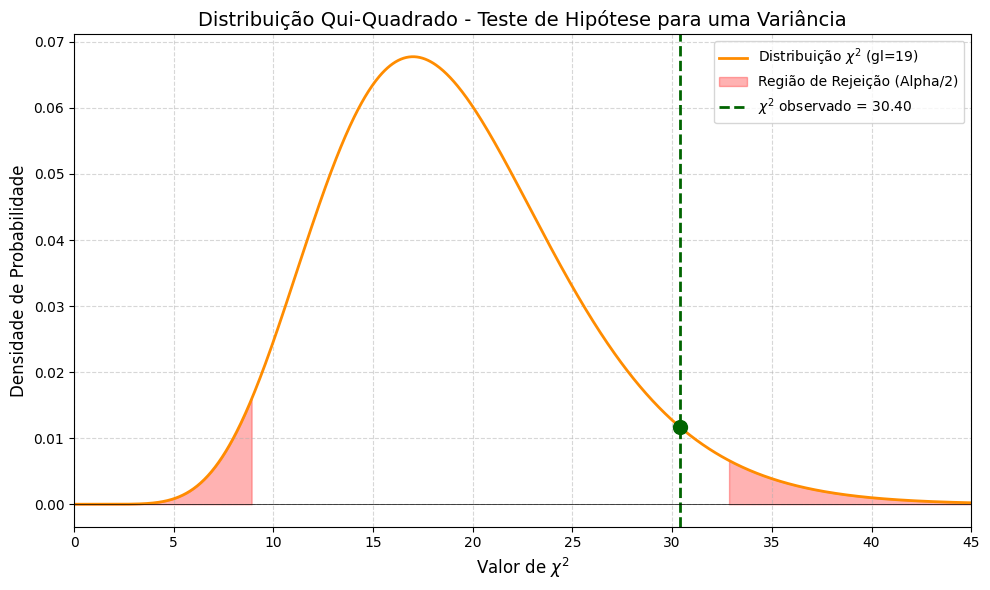

In [6]:
# Definindo o eixo x para a curva Qui-Quadrado
x_q = np.linspace(0, 45, 1000)
y_q = stats.chi2.pdf(x_q, df=grau_liberdade_q)

# Criando o gráfico
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_q, y_q, label=f'Distribuição $\chi^2$ (gl={grau_liberdade_q})', color='darkorange', lw=2)

# Colorir região crítica inferior (cauda esquerda)
x_esq = np.linspace(0, chi2_critico_inf, 100)
ax.fill_between(x_esq, stats.chi2.pdf(x_esq, df=grau_liberdade_q), color='red', alpha=0.3, label='Região de Rejeição (Alpha/2)')

# Colorir região crítica superior (cauda direita)
x_dir = np.linspace(chi2_critico_sup, 45, 100)
ax.fill_between(x_dir, stats.chi2.pdf(x_dir, df=grau_liberdade_q), color='red', alpha=0.3)

# Marcar a estatística de teste observada
ax.axvline(chi2_obs, color='darkgreen', linestyle='--', lw=2, label=f'$\chi^2$ observado = {chi2_obs:.2f}')
ax.scatter([chi2_obs], [stats.chi2.pdf(chi2_obs, df=grau_liberdade_q)], color='darkgreen', s=100, zorder=5)

# Estilização do gráfico
ax.set_title('Distribuição Qui-Quadrado - Teste de Hipótese para uma Variância', fontsize=14)
ax.set_xlabel('Valor de $\chi^2$', fontsize=12)
ax.set_ylabel('Densidade de Probabilidade', fontsize=12)
ax.set_xlim(0, 45)
ax.axhline(0, color='black', lw=0.5)
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

```markdown
### 6. Decisão Estatística e Interpretação

* **Decisão Estatística:**
  * Comparando o valor-p com o nível de significância ($\alpha = 0,05$):
    O valor-p calculado é aproximadamente **0,1116** (11,16%). Como $\text{valor-p} = 0,1116 > \alpha = 0,05$, nós **não rejeitamos a hipótese nula ($H_0$)**.
  * Comparando com os Valores Críticos:
    Os limites da região de aceitação para $gl=19$ são $[8,907; 32,852]$. Como nossa estatística de teste observada $\chi^2_{\text{obs}} = 30,40$ está contida dentro desse intervalo, confirmamos a decisão de não rejeitar $H_0$.

* **Interpretação:**
  Com um nível de significância de 5%, os dados amostrais não fornecem evidências estatísticas suficientes para afirmar que a variabilidade do pH do produto fermentado é diferente do valor de referência de 0,04. Consequentemente, para fins de controle de qualidade, assume-se que o lote recente mantém a uniformidade e a padronização do processo de fermentação estabelecidas originalmente.
```

```markdown
## Resolução da Questão 5: Proporção de produtos com não conformidade microbiológica

### 1. Variável aleatória de interesse e Parâmetro populacional
* **Variável aleatória de interesse ($X$):** Condição microbiológica de uma unidade analisada (0 para conforme, 1 para não conforme).
* **Parâmetro populacional ($p$):** Proporção populacional de unidades de produtos fabricados que apresentam não conformidade microbiológica.

### 2. Formulação das Hipóteses
A equipe deseja investigar se a proporção de não conformidades é superior ao limite tolerável de 5% ($0,05$):
* **Hipótese Nula ($H_0$):** $p \le 0,05$ (A proporção de unidades não conformes está dentro do limite aceitável de 5%).
* **Hipótese Alternativa ($H_a$):** $p > 0,05$ (A proporção de unidades não conformes é superior ao limite tolerado de 5%).

### 3. Procedimento Estatístico Adequado e Verificação das Condições
O procedimento adequado é o **Teste Z para uma proporção populacional** (unilateral à direita).

**Verificação das condições para a aproximação pela Normal:**
1. Amostra aleatória e independente de tamanho $n = 200$.
2. Condição de sucesso-fracasso sob $H_0$ ($p_0 = 0,05$):
   * $n \cdot p_0 = 200 \cdot 0,05 = 10 \ge 10$
   * $n \cdot (1 - p_0) = 200 \cdot 0,95 = 190 \ge 10$

Como ambas as condições são satisfeitas, podemos utilizar a aproximação por uma distribuição Normal Padrão para a estatística do teste.
```

In [7]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Dados do enunciado
p_0 = 0.05       # Proporção sob H0
n = 200          # Tamanho da amostra
x_sucessos = 16  # Unidades não conformes encontradas
alpha_p = 0.05   # Nível de significância

# 4. Proporção amostral e Estatística de teste
p_barra = x_sucessos / n

# Erro padrão sob H0
erro_padrao_p = np.sqrt((p_0 * (1 - p_0)) / n)

# Estatística de teste Z
z_obs_p = (p_barra - p_0) / erro_padrao_p

# 5. Cálculo do valor-p (unilateral à direita)
p_valor_prop = 1 - stats.norm.cdf(z_obs_p)

print(f"Proporção Amostral (p-barra): {p_barra:.4f} (ou {p_barra*100:.2f}%)")
print(f"Erro Padrão da Proporção: {erro_padrao_p:.4f}")
print(f"Estatística de Teste (Z observado): {z_obs_p:.4f}")
print(f"Valor-p: {p_valor_prop:.4f} (ou {p_valor_prop*100:.2f}%)")

Proporção Amostral (p-barra): 0.0800 (ou 8.00%)
Erro Padrão da Proporção: 0.0154
Estatística de Teste (Z observado): 1.9467
Valor-p: 0.0258 (ou 2.58%)


```markdown
### 5. Representação Gráfica da Distribuição Normal Padrão para a Proporção
Vamos gerar o gráfico da distribuição normal com a marcação do $Z$ observado e da região crítica correspondente ao nível de significância de 5%.

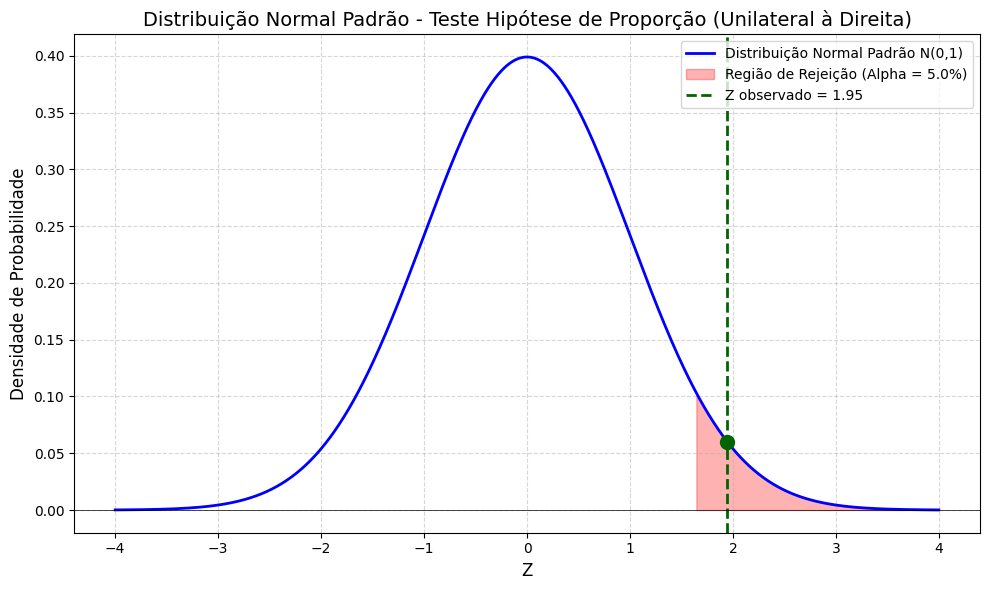

In [8]:
# Definindo o eixo x para a curva normal padrão
x_norm = np.linspace(-4, 4, 1000)
y_norm = stats.norm.pdf(x_norm, 0, 1)

# Criando o gráfico
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x_norm, y_norm, label='Distribuição Normal Padrão N(0,1)', color='blue', lw=2)

# Valor crítico para alpha = 5% (unilateral à direita)
z_critico_p = stats.norm.ppf(1 - alpha_p)

# Colorir região crítica de rejeição
x_rejeicao_p = np.linspace(z_critico_p, 4, 100)
ax.fill_between(x_rejeicao_p, stats.norm.pdf(x_rejeicao_p), color='red', alpha=0.3, label=f'Região de Rejeição (Alpha = {alpha_p*100}%)')

# Marcar o Z observado no gráfico
ax.axvline(z_obs_p, color='darkgreen', linestyle='--', lw=2, label=f'Z observado = {z_obs_p:.2f}')
ax.scatter([z_obs_p], [stats.norm.pdf(z_obs_p)], color='darkgreen', s=100, zorder=5)

# Estilização do gráfico
ax.set_title('Distribuição Normal Padrão - Teste Hipótese de Proporção (Unilateral à Direita)', fontsize=14)
ax.set_xlabel('Z', fontsize=12)
ax.set_ylabel('Densidade de Probabilidade', fontsize=12)
ax.axhline(0, color='black', lw=0.5)
ax.legend(loc='upper right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

```markdown
### 6. Decisão Estatística e Conclusão

* **Decisão Estatística:**
  * Comparando o valor-p com o nível de significância ($\alpha = 0,05$):
    O valor-p calculado é de aproximadamente **0,0256** (2,56%). Como $\text{valor-p} = 0,0256 < \alpha = 0,05$, nós **rejeitamos a hipótese nula ($H_0$)**.
  * Comparando com o Valor Crítico:
    O valor crítico para $5\%$ unilateral é $1,645$. Como nossa estatística observada $Z_{\text{obs}} = 1,95$ é maior que $1,645$, ela se encontra firmemente dentro da região de rejeição da hipótese nula.

* **Interpretação:**
  A um nível de significância de 5%, os resultados fornecem evidências estatísticas de que a proporção de unidades não conformes do lote avaliado é superior ao limite estipulado de 5% (com proporção amostral observada de 8,0%). No contexto da segurança de alimentos e controle de qualidade, esse veredito indica que o lote em questão apresenta desvios sanitários significativos. A equipe de segurança deve suspender o lote correspondente e abrir imediatamente uma investigação para identificar falhas no processo de higienização, processamento ou estocagem.
```